# Comparación común y análisis multivariado
Se verifican hashes de configuración, motor, datos, contrato, horizonte y seeds antes de comparar. Se usa exclusivamente el conjunto común 31–100. La solución NSGA-II ilustrativa se elige por distancia normalizada al ideal con medias de búsqueda congeladas, nunca por el mejor resultado reservado.

Los IC bootstrap 95% son puntuales y condicionales a las instalaciones guardadas; no corrigen selección ni multiplicidad. RANDOM se agrega por seed antes de formar diferencias pareadas.

In [1]:
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'config/project2/base.yaml').exists())
sys.path.insert(0, str(ROOT / 'src'))
from bee_sim.analysis.project2_comparison import build_comparison
data = build_comparison(ROOT)
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})


In [2]:
display(data['audit'])
display(data['summary'])
display(data['paired'])

,method,file,original_rows,holdout_rows,solutions,holdout_replications,sha256,config_hash,engine_hash,input_hash,metric_contract_hash,engine_version,K,scenario,mode,resource_unit
0,RANDOM,random_results.csv,3000,2100,30,70,1ea1b9c7e5dc5bf52b604d6b02c4fb4cff7da32f687793...,32b62484aff30d3403707694d538d776600f9dec8381d4...,6a032bf015293cabcaa47dc8b0a3cd72e8b8d3e1061dee...,df45f2a5654d783531ea18cb0fb116eab76f3c215b8499...,290ae72c96171b1ab6055b939488527f02d4eab04cfd52...,project2-synthetic-1.1.0,5,synthetic_base_v1,synthetic,synthetic_RU
1,GREEDY,greedy_results.csv,100,70,1,70,de94eeac4dd5ee43a26246dc57908c0211351fdeec1547...,32b62484aff30d3403707694d538d776600f9dec8381d4...,6a032bf015293cabcaa47dc8b0a3cd72e8b8d3e1061dee...,df45f2a5654d783531ea18cb0fb116eab76f3c215b8499...,290ae72c96171b1ab6055b939488527f02d4eab04cfd52...,project2-synthetic-1.1.0,5,synthetic_base_v1,synthetic,synthetic_RU
2,NSGA2,nsga2_results.csv,3430,3430,49,70,31f59cf036910e623028957b73db3b44d0ddbfaccf81bd...,32b62484aff30d3403707694d538d776600f9dec8381d4...,6a032bf015293cabcaa47dc8b0a3cd72e8b8d3e1061dee...,df45f2a5654d783531ea18cb0fb116eab76f3c215b8499...,290ae72c96171b1ab6055b939488527f02d4eab04cfd52...,project2-synthetic-1.1.0,5,synthetic_base_v1,synthetic,synthetic_RU


,method,metric,mean,ci95_low,ci95_high,n_seeds,undefined_seeds,solution,interval_scope
0,RANDOM,total_resource_obtained,7.216620e+02,7.176912e+02,7.257656e+02,70,0,mean_of_30_installations,conditional_on_fixed_installations_common_seed...
1,RANDOM,mean_resource_per_hive,1.443324e+02,1.435382e+02,1.451531e+02,70,0,mean_of_30_installations,conditional_on_fixed_installations_common_seed...
2,RANDOM,min_resource_per_hive,1.061084e+02,1.056056e+02,1.066170e+02,70,0,mean_of_30_installations,conditional_on_fixed_installations_common_seed...
3,RANDOM,mean_distance_m,1.618409e+03,1.617146e+03,1.619605e+03,70,0,mean_of_30_installations,conditional_on_fixed_installations_common_seed...
4,RANDOM,total_distance_m,1.754259e+06,1.741466e+06,1.767471e+06,70,0,mean_of_30_installations,conditional_on_fixed_installations_common_seed...
5,RANDOM,p95_distance_m,2.852905e+03,2.851711e+03,2.854029e+03,70,0,mean_of_30_installations,conditional_on_fixed_installations_common_seed...
6,RANDOM,competition_pressure,3.218465e-04,2.926669e-04,3.540396e-04,70,0,mean_of_30_installations,conditional_on_fixed_installations_common_seed...
7,RANDOM,hive_balance_jain,9.549280e-01,9.541059e-01,9.557910e-01,70,0,mean_of_30_installations,conditional_on_fixed_installations_common_seed...
8,RANDOM,patches_used_count,2.393571e+02,2.385585e+02,2.401933e+02,70,0,mean_of_30_installations,conditional_on_fixed_installations_common_seed...
9,GREEDY,total_resource_obtained,9.143756e+02,9.068172e+02,9.221132e+02,70,0,solution_001,conditional_on_fixed_installations_common_seed...


,contrast,metric,difference,ci95_low,ci95_high,n_pairs,undefined_pairs,bootstrap_seed
0,GREEDY-RANDOM,total_resource_obtained,192.713657,188.610956,196.647694,70,0,2017
1,GREEDY-RANDOM,mean_resource_per_hive,38.542731,37.722191,39.329539,70,0,2017
2,GREEDY-RANDOM,min_resource_per_hive,52.799612,50.791999,54.667726,70,0,2017
3,GREEDY-RANDOM,mean_distance_m,-299.670605,-304.181831,-295.052997,70,0,2017
4,GREEDY-RANDOM,total_distance_m,-324603.811598,-329346.805669,-319848.558604,70,0,2017
5,GREEDY-RANDOM,p95_distance_m,-182.663022,-190.462862,-175.020794,70,0,2017
6,GREEDY-RANDOM,competition_pressure,-0.000068,-0.000180,0.000061,70,0,2017
7,GREEDY-RANDOM,hive_balance_jain,0.033571,0.032239,0.034820,70,0,2017
8,GREEDY-RANDOM,patches_used_count,-7.314286,-8.827667,-5.749369,70,0,2017
9,NSGA2-RANDOM,total_resource_obtained,206.124715,201.769722,210.503982,70,0,2017


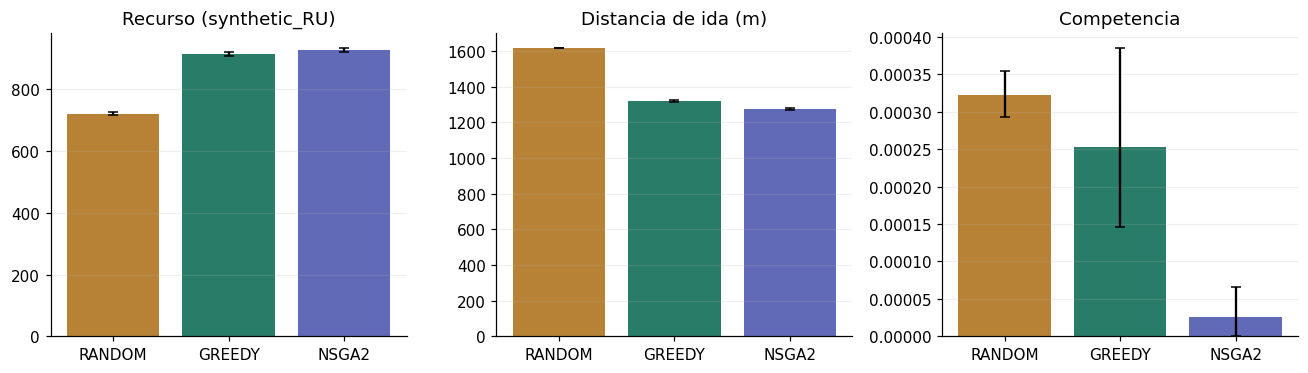

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(12, 3.5))
for ax, metric, label in zip(axes, ['total_resource_obtained','mean_distance_m','competition_pressure'], ['Recurso (synthetic_RU)','Distancia de ida (m)','Competencia']):
    rows = data['summary'].query('metric == @metric').set_index('method').loc[['RANDOM','GREEDY','NSGA2']]
    ax.bar(rows.index, rows['mean'], color=['#b78235','#287c68','#606ab7'])
    ax.errorbar(range(3), rows['mean'], yerr=[rows['mean']-rows.ci95_low, rows.ci95_high-rows['mean']], fmt='none', color='black', capsize=3)
    ax.set_title(label)
    ax.grid(axis='y', alpha=.2)
fig.tight_layout()
plt.show()

## Compromisos y correlaciones
Se muestran 32 instalaciones físicas diferentes del frente archivado. Correlaciones describen estas alternativas seleccionadas y no establecen relaciones causales ni generalizan a todos los sitios posibles.

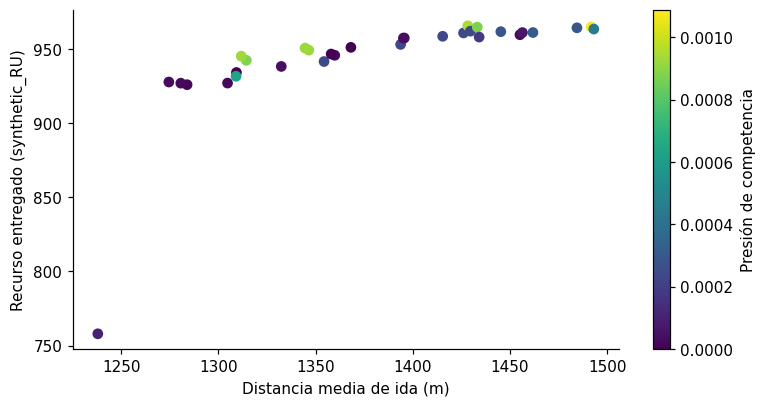

,total_resource_obtained,mean_distance_m,competition_pressure,hive_balance_jain
total_resource_obtained,1.000000,0.939516,0.477814,0.642962
mean_distance_m,0.939516,1.000000,0.333333,0.639663
competition_pressure,0.477814,0.333333,1.000000,0.500183
hive_balance_jain,0.642962,0.639663,0.500183,1.000000


In [4]:
cloud = data['nsga_installations'].query('not physical_duplicate')
fig, ax = plt.subplots(figsize=(8, 4))
points = ax.scatter(cloud.mean_distance_m, cloud.total_resource_obtained, c=cloud.competition_pressure, cmap='viridis')
fig.colorbar(points, ax=ax, label='Presión de competencia')
ax.set(xlabel='Distancia media de ida (m)', ylabel='Recurso entregado (synthetic_RU)')
plt.show()
display(cloud[['total_resource_obtained','mean_distance_m','competition_pressure','hive_balance_jain']].corr(method='spearman'))

## Alcance
Mayor recurso y menor distancia pueden entrar en conflicto. No se declara un ganador universal: se deben ponderar objetivos y revisar sensibilidad. Las unidades de recurso son sintéticas; Dryad observa flores y visitas, no RU, néctar ni polinización efectiva.